In [2]:
#IMPORTS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [3]:
#read DataFrame
df=pd.read_csv('000_df_RAW.csv')
# lieux=pd.read_csv('000_lieux_RAW.csv')

C:\Users\hayadi\AppData\Local\Temp\ipykernel_30516\399459084.py:2: DtypeWarning: Columns (8,12,27,33,35,36,37,38,40,45,46,50,51) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv('000_df_RAW.csv')


In [5]:
#pre-processing
# df.an.replace({2019:19,2021:21,2020:20},inplace=True)
df.an.replace({5:2005,6:2006,7:2007,8:2008,9:2009},inplace=True)
df.an.replace({10:2010,11:2011,12:2012,13:2013,14:2014,15:2015,16:2016,17:2017,18:2018},inplace=True)

#date accident (I need to add hrmn...)
df['date'] = df['an'].astype(str) + '-' + df['mois'].astype(str) + '-' + df['jour'].astype(str)
df['date'] = pd.to_datetime(df['date'], yearfirst = True)

#age usagers + rang
df['age']=df.date.dt.year-df.an_nais
age_rang=[0,18,30,50,80,120]
labels_age_rang=['<18','18-30','30-50','50-80','80<']
df['age_rang']=pd.cut(df.age,bins=age_rang,labels=labels_age_rang)

df['conducteur']=(df.place==1).astype(int)

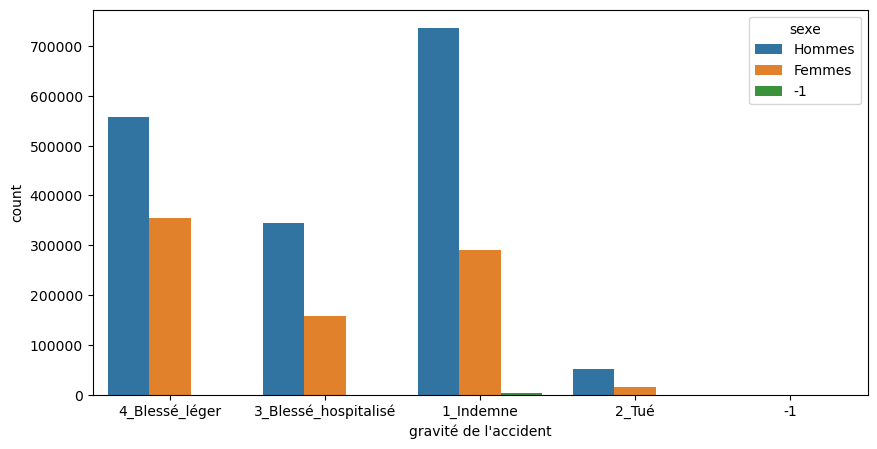

In [68]:
#plot: count accident vs gravité
df.sexe.replace({1:'Hommes',2:'Femmes'},inplace=True)
df.grav.replace({1: '1_Indemne',2 : '2_Tué', 3 : '3_Blessé_hospitalisé', 4 : '4_Blessé_léger'},inplace=True)
fig, ax = plt.subplots(figsize=(10,5))
sns.countplot(x=df.grav,hue=df.sexe,ax=ax);
plt.xlabel("gravité de l'accident");



C:\Users\hayadi\AppData\Local\Temp\ipykernel_35336\4055543929.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.place[df.place!=1]=99


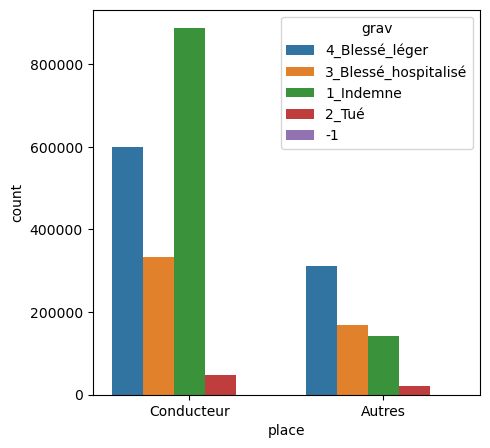

In [67]:
#plot: count gravé vs (conducteur or not)
fig, ax = plt.subplots(figsize=(5,5))
df.place[df.place!=1]=99
ax2=sns.countplot(x=df.place,hue=df.grav,ax=ax);
ax2.set_xticklabels(['Conducteur', 'Autres']);
# plt.title('Gravité en fonction du conducteur vs autres');

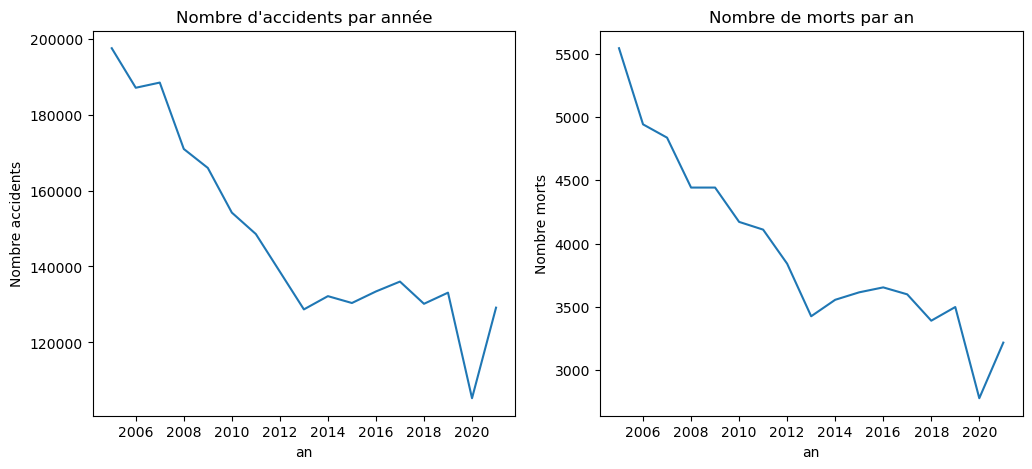

In [171]:
#plot Nb accidents/morts vs année
nb_acc=df.groupby('an').size()
nb_mort=df[df.grav==2].groupby('an').size()
df_plot=pd.DataFrame([nb_acc,nb_mort]).T
df_plot.rename(columns={0: 'Nombre accidents',1: 'Nombre morts'}, inplace=True)
df_plot['year']=df_plot.index
# df_plot.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.lineplot(x='an',y='Nombre accidents',data=df_plot,ax=axes[0]);
axes[0].set_title('Nombre d\'accidents par année')
sns.lineplot(x='an',y='Nombre morts',data=df_plot,ax=axes[1]);
axes[1].set_title('Nombre de morts par an');





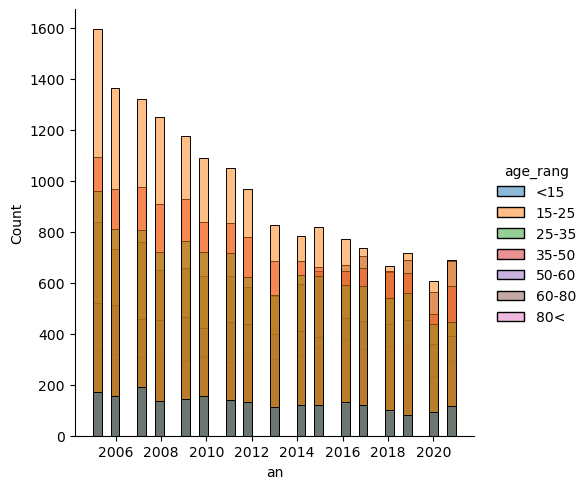

In [137]:
#plot: accident count sur les années en fonction de la tranche d'age
df2=df
sns.displot(x='an', hue='age_rang', data=df[df.grav==2]);

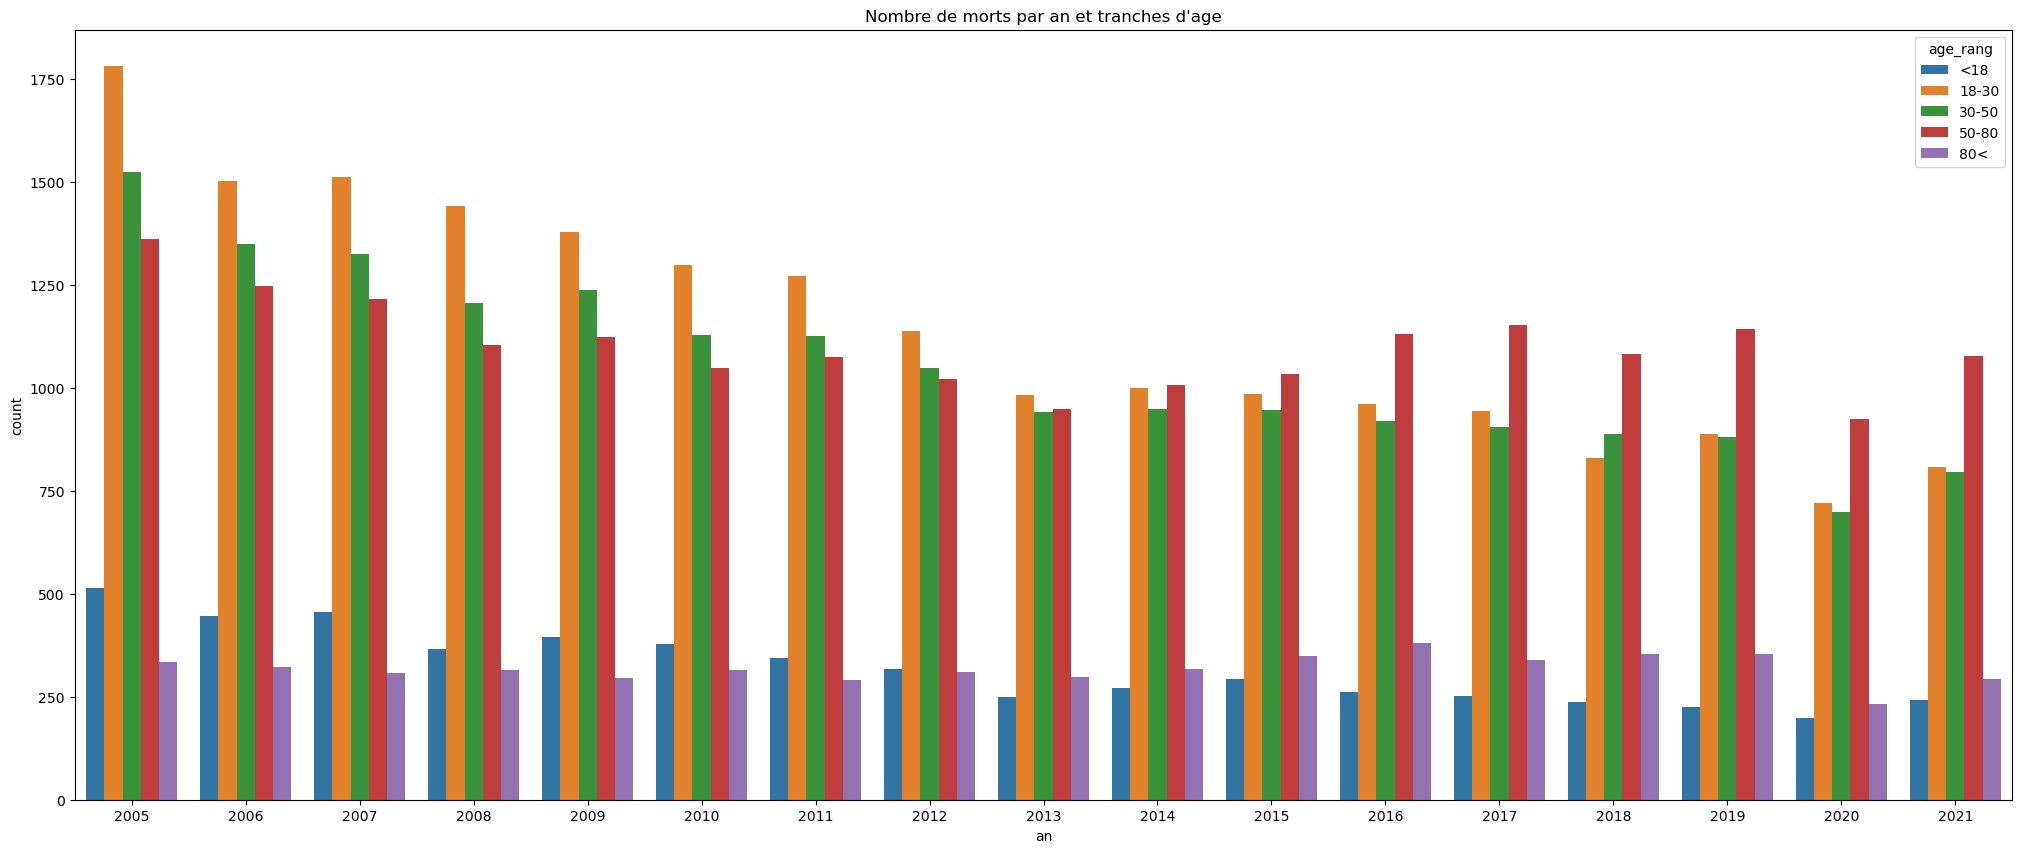

In [6]:
#plot: Nb morts par an et en fonction de l'age
fig, ax = plt.subplots(figsize=(25,10))
sns.countplot(x='an', hue='age_rang', data=df[df.grav==2],ax=ax); #
# sns.countplot(x='an', hue='age_rang', data=df[(df.grav==2) & (df.conducteur==1)],ax=ax);

plt.title("Nombre de morts par an et tranches d'age");

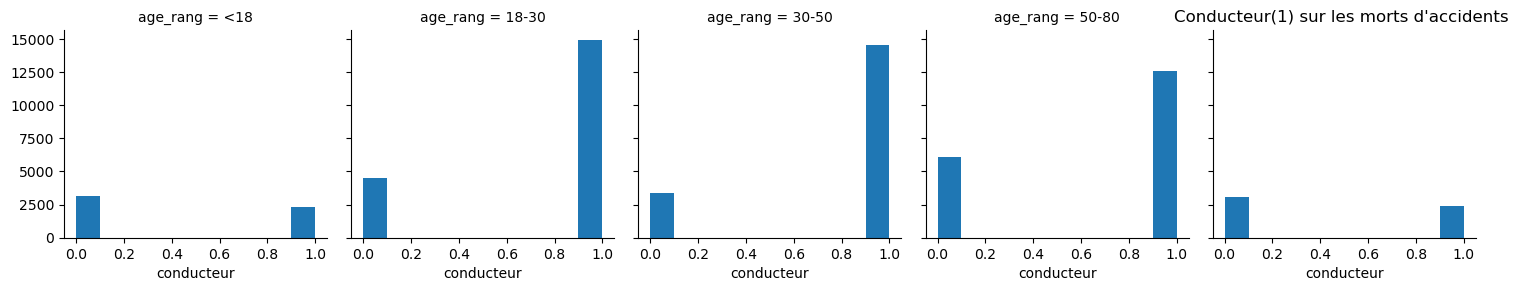

In [160]:
#plot: morts par tranche d'age (si le mort est conducteur ou non)
g = sns.FacetGrid(df[df.grav==2], col='age_rang')
g.map(plt.hist, 'conducteur');
plt.title('Conducteur(1) sur les morts d\'accidents ');

Text(0.5, 0, 'Age du conducteur')

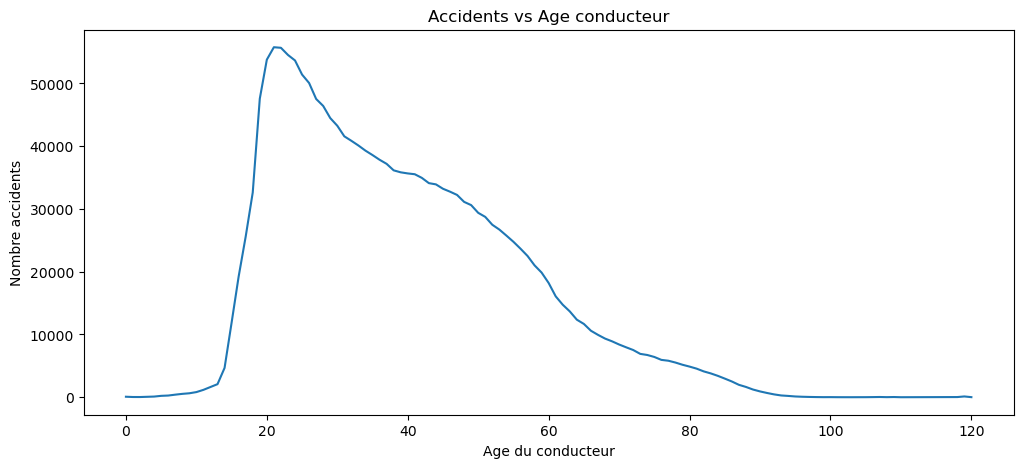

In [181]:
#plot: Nb d'accidents en fonction de l'age 
nb_acc=df[df.conducteur==1].groupby('age').size()
nb_mort=df[(df.grav==2) & (df.conducteur==1)].groupby('age').size()
df_plot=pd.DataFrame([nb_acc,nb_mort]).T
df_plot.rename(columns={0: 'Nombre accidents',1: 'Nombre morts'}, inplace=True)
df_plot['age']=df_plot.index
# df_plot.reset_index()

fig, axes = plt.subplots(figsize=(12, 5))
sns.lineplot(x='age',y='Nombre accidents',data=df_plot,ax=axes);
axes.set_title('Accidents vs Age conducteur')
axes.set_xlabel('Age du conducteur')
# sns.lineplot(x='age',y='Nombre morts',data=df_plot,ax=axes[1]);
# axes[1].set_title('Nombre de morts par age');
# axes[1].set_xlabel('Age du conducteur');

In [205]:
#read carac juste pour faire la map
carac=pd.read_csv('000_carac_RAW.csv')
import geopandas as gpd
from shapely.geometry import Point

C:\Users\hayadi\AppData\Local\Temp\ipykernel_4524\1273538328.py:1: DtypeWarning: Columns (4,10,12,13,14,15) have mixed types. Specify dtype option on import or set low_memory=False.
  carac=pd.read_csv('000_carac_RAW.csv')


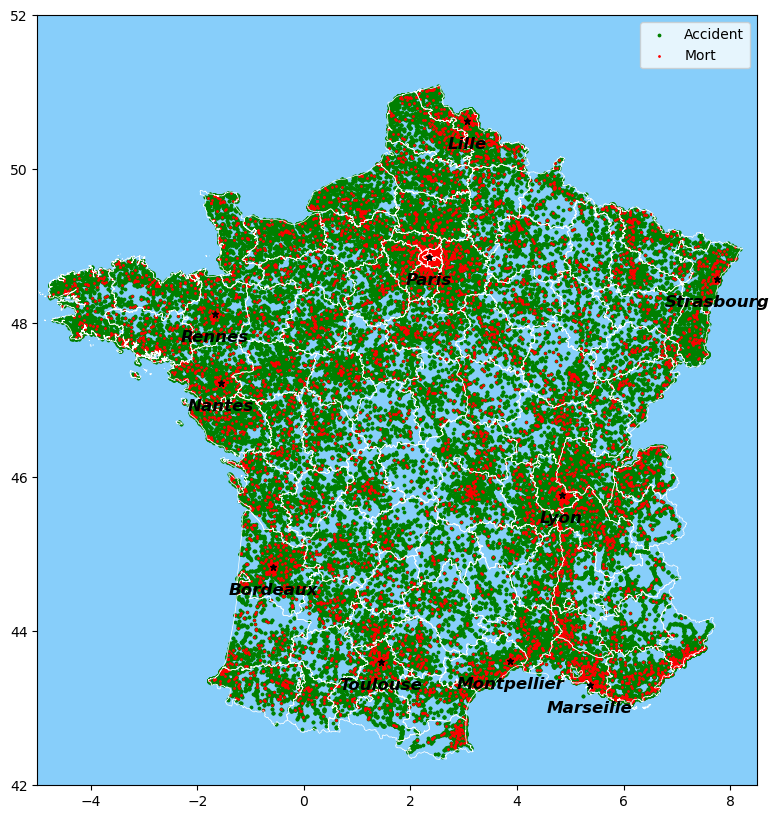

In [248]:
#map France accidents et morts
carac2=df
carac2 = carac2.drop(carac2[(carac2['dep'] == '2A') | (carac2['dep'] == '2B')].index)
carac2.dep=carac2.dep.astype(int)


carac_m = carac2[carac2['dep']<=95]
carac_m = carac_m[(carac_m['lat']!=0.0) & (carac_m['long']!=0.0)].dropna(subset=['lat', 'long'], axis=0)

carac_m.lat = carac_m.lat.str.replace(',', '.')
carac_m.lat =carac_m.lat.replace('-', float('nan'))
carac_m.lat=carac_m.lat.astype(float)
carac_m.long = carac_m.long.str.replace(',', '.')
carac_m.long =carac_m.long.replace('-', float('nan'))
carac_m.long=carac_m.long.astype(float)
# carac_m = carac_m.drop(carac_m[(carac_m['lat'] <0) | (carac_m['long'] <0)].index)



geometry = [Point(xy) for xy in zip(carac_m['long'], carac_m['lat'])]
geo_df = gpd.GeoDataFrame(carac_m, geometry=geometry)

fig, ax = plt.subplots(figsize=(16, 10))
ax.set_facecolor('lightskyblue') 
geo_df.plot(ax=ax,markersize=3,color='green',label='Accident')
geo_df[geo_df['grav']==2].plot(ax=ax, markersize=1, color='red', label='Mort')
ax.set_xlim(-5, 8.5)  
ax.set_ylim(42, 52)
plt.legend();

#coordonnées villes francaise
villes_coords = {
    'Bordeaux': (-0.5792, 44.8378),
    'Lille': (3.0573, 50.6292),
    'Rennes': (-1.6743, 48.1172),
    'Nantes': (-1.5536, 47.2184),
    'Marseille': (5.3698, 43.2965),
    'Lyon': (4.8357, 45.7640),
    'Toulouse': (1.4442, 43.6045),
    'Montpellier': (3.8767, 43.6119),
    'Paris': (2.3522, 48.8566),  # Coordonnées GPS de Paris
    'Strasbourg': (7.7521, 48.5734)  # Coordonnées GPS de Strasbourg
}

#contour France
# france = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
# france.boundary.plot(ax=ax, linewidth=2, color='white')

#contour Departements
departements = gpd.read_file('https://github.com/gregoiredavid/france-geojson/raw/master/departements.geojson')
departements.boundary.plot(ax=ax, linewidth=0.5, color='white')

# Placer villes 
for ville, coords in villes_coords.items():
    ax.plot(coords[0], coords[1], marker='*', markersize=5, color='k')
    ax.text(coords[0], coords[1] - 0.3, ville, color='k', fontsize=12, ha='center',weight='bold',style='italic', va='center');



c:\Users\hayadi\AppData\Local\anaconda3\Lib\site-packages\geopandas\geodataframe.py:1475: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  result = super().__getitem__(key)


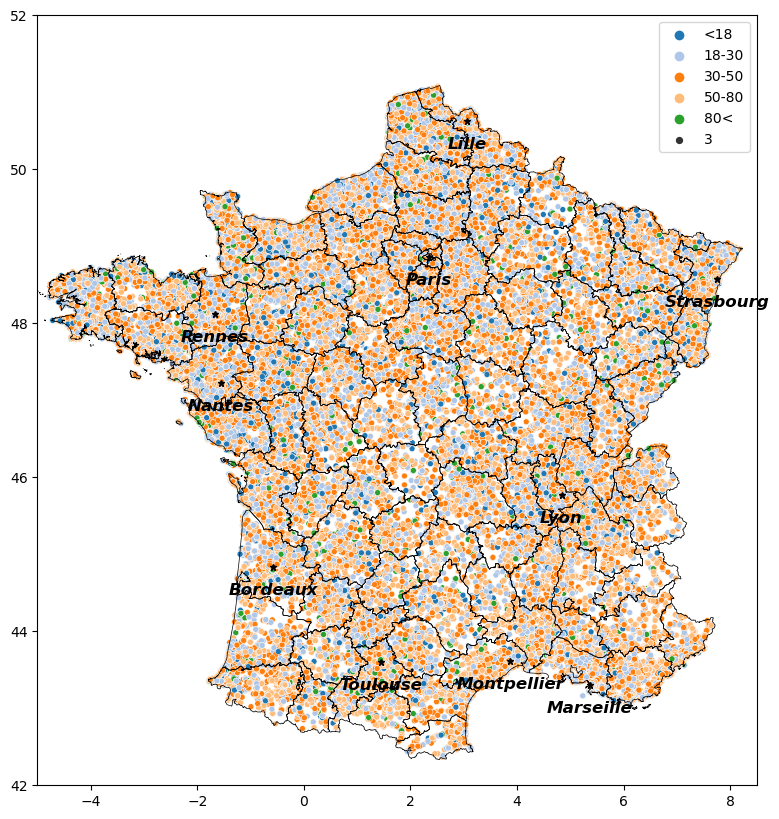

In [271]:
#map France tranche d'age (pas interessante...)
fig, ax = plt.subplots(figsize=(16, 10))
# ax.set_facecolor('lightskyblue') 

sns.scatterplot(x=geo_df.geometry.x, y=geo_df.geometry.y, data=geo_df[df.conducteur==1], size=3, hue='age_rang', palette='tab20', legend='brief', ax=ax)

ax.set_xlim(-5, 8.5)  
ax.set_ylim(42, 52)
plt.legend()

for ville, coords in villes_coords.items():
    ax.plot(coords[0], coords[1], marker='*', markersize=5, color='k')
    ax.text(coords[0], coords[1] - 0.3, ville, color='k', fontsize=12, ha='center', weight='bold', style='italic', va='center')

departements = gpd.read_file('https://github.com/gregoiredavid/france-geojson/raw/master/departements.geojson')
departements.boundary.plot(ax=ax, linewidth=0.5, color='black');